# AIE322 — Advanced Machine Learning
**Practical Assignment:** E-Commerce Customer Churn Classification  
**Student Name:** Abdelrhman Mohamed Ahmed Al Ghonimi  
**Student ID:** 223101228  
**Institution:** New Mansoura University (NMU) — Faculty of Computer Science & Engineering  
**Dataset:** E-Commerce Customer Churn Dataset (Kaggle)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## Part 1: Data Cleaning, EDA & Reproducible Splitting
### 1.1 Initial Inspection & Cleaning

In [2]:
if os.path.exists("E Commerce Dataset.xlsx"):
    try:
        df = pd.read_excel("E Commerce Dataset.xlsx", sheet_name="E Comm")
    except ValueError:
        df = pd.read_excel("E Commerce Dataset.xlsx")
elif os.path.exists("E Commerce Dataset.csv"):
    df = pd.read_csv("E Commerce Dataset.csv")
else:
    raise FileNotFoundError("Place 'E Commerce Dataset.xlsx' or 'E Commerce Dataset.csv' in the working directory.")

print("Original shape:", df.shape)
df.head()

Original shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
# Drop non-predictive CustomerID column
if "CustomerID" in df.columns:
    df = df.drop(columns=["CustomerID"])

print("Shape after dropping CustomerID:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

print("\nMissing values per column:")
missing = df.isnull().sum()
print(missing[missing > 0])

print("\nData types:")
print(df.dtypes)

Shape after dropping CustomerID: (5630, 19)
Duplicate rows: 556

Missing values per column:
Tenure                         231
WarehouseToHome                221
HourSpendOnApp                 230
OrderAmountHikeFromlastYear    252
CouponUsed                     210
OrderCount                     243
DaySinceLastOrder              288
dtype: int64

Data types:
Churn                            int64
Tenure                         float64
PreferredLoginDevice            object
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode            object
Gender                          object
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                object
SatisfactionScore                int64
MaritalStatus                   object
NumberOfAddress                  int64
Complain                         int64
OrderAmountHikeFromlastYear    float64
CouponUsed                     float64
OrderCount   

In [4]:
# Check outliers using IQR method on continuous numerical columns
num_check_cols = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder", "OrderAmountHikeFromlastYear"]
outlier_summary = {}

for col in num_check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = {"Q1": round(q1, 2), "Q3": round(q3, 2), "Lower": round(lower, 2), "Upper": round(upper, 2), "Outlier_Count": int(count)}

pd.DataFrame(outlier_summary).T

,Q1,Q3,Lower,Upper,Outlier_Count
Tenure,2.00,16.00,-19.00,37.0,4.0
WarehouseToHome,9.00,20.00,-7.50,36.5,2.0
CashbackAmount,145.92,197.95,67.86,276.0,382.0
DaySinceLastOrder,2.00,7.00,-5.50,14.5,57.0
OrderAmountHikeFromlastYear,13.00,18.00,5.50,25.5,29.0


Note on outliers: Extreme values in `Tenure`, `WarehouseToHome`, and `CashbackAmount` reflect valid customer edge cases (e.g., long-tenured users or distant delivery addresses) rather than sensor/entry errors. Keeping them preserves real customer behavior, while `SimpleImputer(strategy="median")` prevents skew during imputation.

### 1.2 Exploratory Data Analysis (EDA)

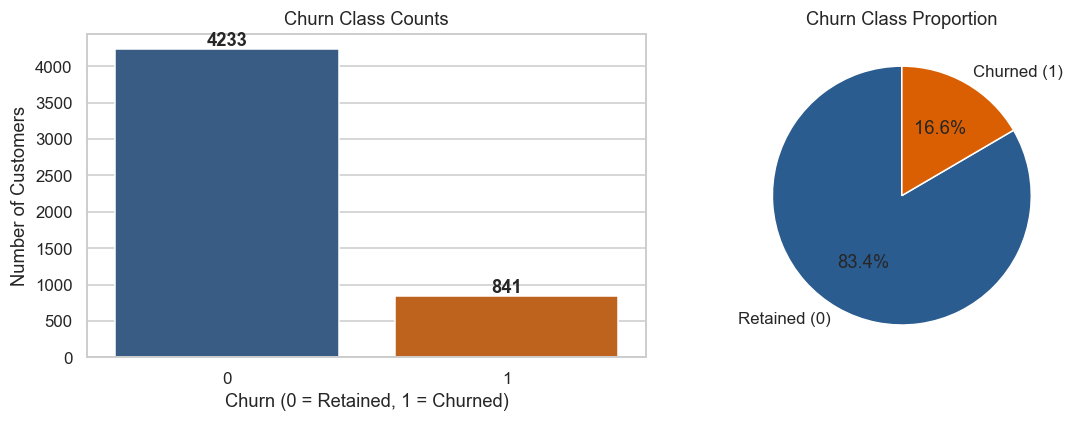

In [5]:
# Class balance of target variable Churn
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

churn_counts = df["Churn"].value_counts()
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=["#2b5c8f", "#d95f02"], ax=axes[0])
axes[0].set_title("Churn Class Counts")
axes[0].set_xlabel("Churn (0 = Retained, 1 = Churned)")
axes[0].set_ylabel("Number of Customers")
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 50, str(v), ha="center", fontweight="bold")

axes[1].pie(
    churn_counts.values,
    labels=["Retained (0)", "Churned (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2b5c8f", "#d95f02"]
)
axes[1].set_title("Churn Class Proportion")

plt.tight_layout()
plt.show()

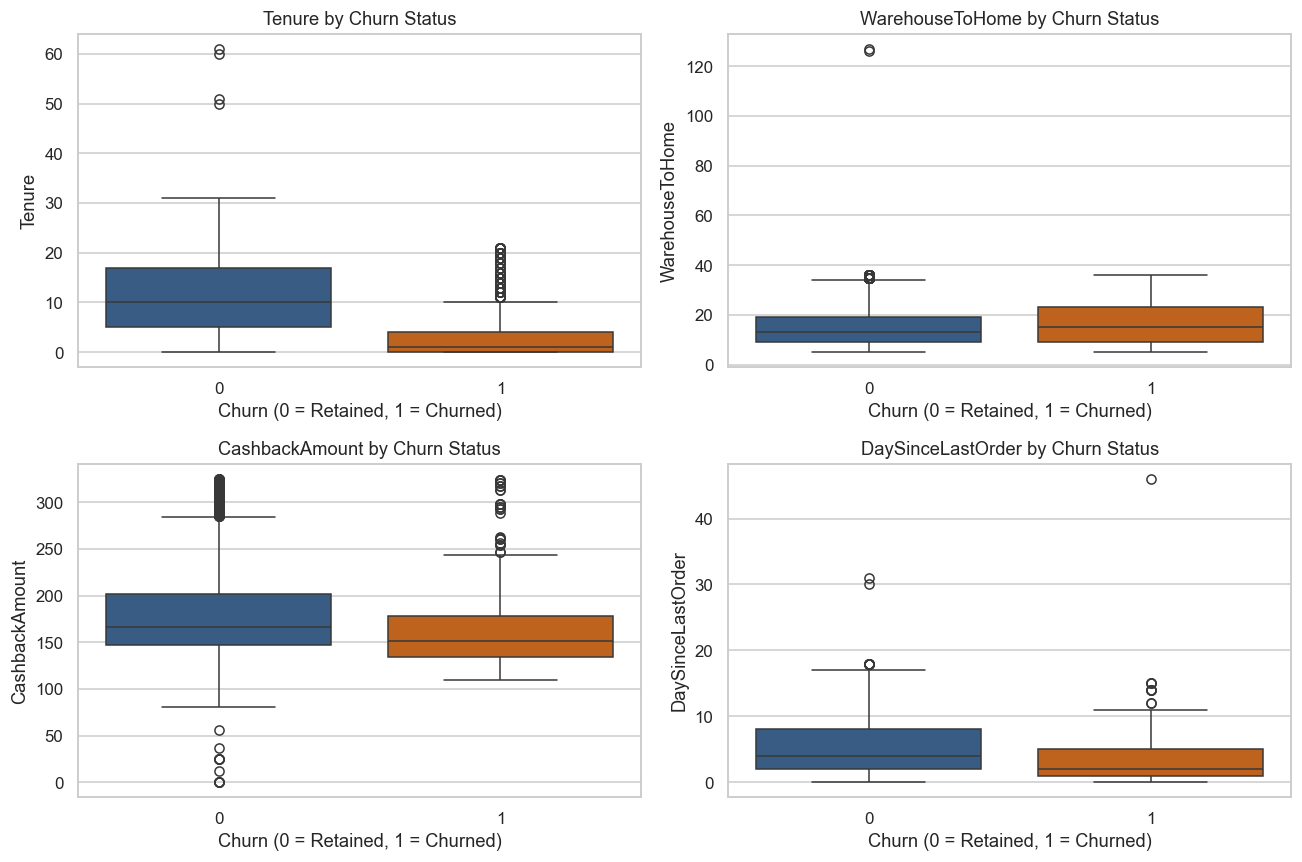

In [6]:
# Distribution of key numerical features across Churn status
key_num_features = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), key_num_features):
    sns.boxplot(data=df, x="Churn", y=col, palette=["#2b5c8f", "#d95f02"], ax=ax)
    ax.set_title(f"{col} by Churn Status")
    ax.set_xlabel("Churn (0 = Retained, 1 = Churned)")

plt.tight_layout()
plt.show()

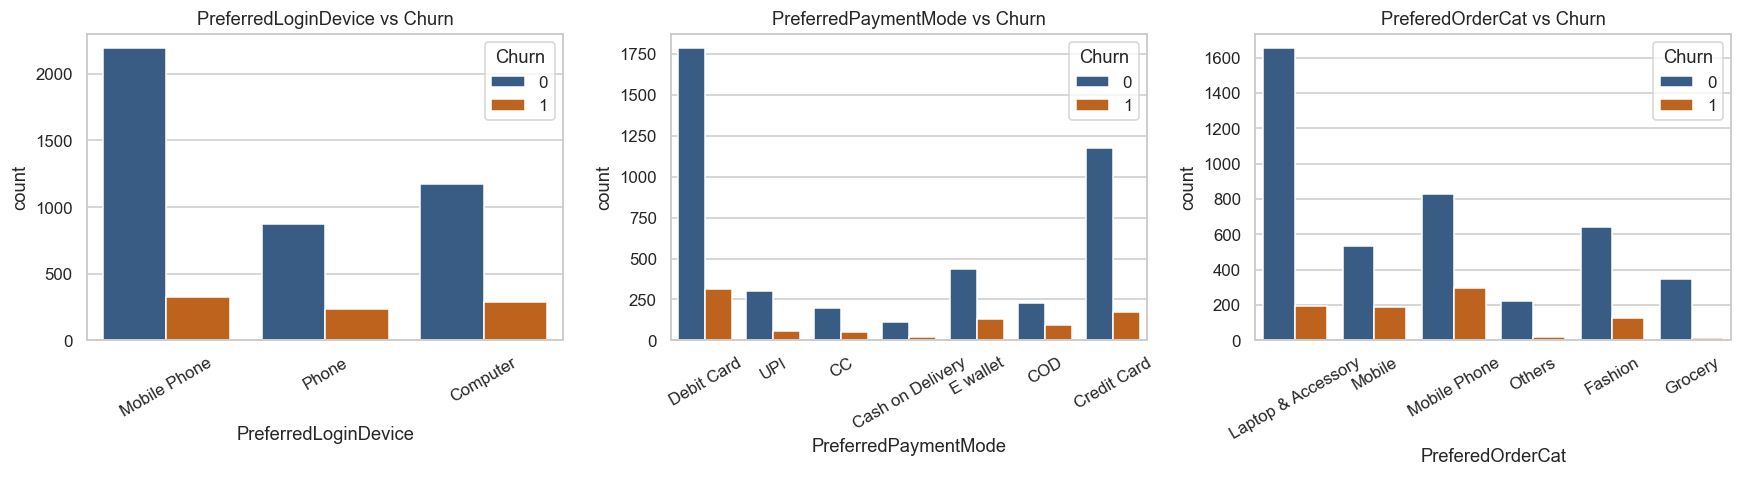

In [7]:
# Key categorical features vs Churn
key_cat_features = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, key_cat_features):
    sns.countplot(data=df, x=col, hue="Churn", palette=["#2b5c8f", "#d95f02"], ax=ax)
    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### 1.3 Reproducible Train/Test Split

In [8]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print("Train Churn rate:", round(y_train.mean(), 4))
print("Test Churn rate: ", round(y_test.mean(), 4))

X_train shape: (4059, 18) | X_test shape: (1015, 18)
Train Churn rate: 0.1658
Test Churn rate:  0.1655


**Analytical Question — Why is setting `random_state` essential when splitting datasets in scikit-learn?**

`train_test_split` shuffles the dataset using a pseudo-random number generator before partitioning it into training and test subsets. Without a fixed `random_state` seed:
1. **Reproducibility:** Every execution produces a different train/test split, causing evaluation metrics (accuracy, F1-score, etc.) to fluctuate across runs and making results impossible to reproduce reliably.
2. **Fair Model Comparison:** When comparing different models or tuning hyperparameters, all experiments must be evaluated on the exact same test set; otherwise, performance differences could simply come from an easier or harder random split rather than true model improvement.
3. **Preventing Subtle Data Leakage Across Iterations:** Repeated re-splitting during experimentation exposes different subsets to validation decisions over time, which compromises the integrity of the holdout evaluation set.

## Part 2: Preprocessing Pipelines (`ColumnTransformer` & `Pipeline`)
### 2.1 Numerical & Categorical Pipelines + Attribute Inspection

In [9]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical columns: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [10]:
# 1. Numerical pipeline & SimpleImputer attribute inspection
num_imputer = SimpleImputer(strategy="median")
num_imputer.fit(X_train[num_cols])

print("Learned medians (.statistics_):")
for col, med in zip(num_cols, num_imputer.statistics_):
    print(f"  {col:28s}: {med}")

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

Learned medians (.statistics_):
  Tenure                      : 9.0
  CityTier                    : 1.0
  WarehouseToHome             : 13.0
  HourSpendOnApp              : 3.0
  NumberOfDeviceRegistered    : 4.0
  SatisfactionScore           : 3.0
  NumberOfAddress             : 3.0
  Complain                    : 0.0
  OrderAmountHikeFromlastYear : 15.0
  CouponUsed                  : 1.0
  OrderCount                  : 2.0
  DaySinceLastOrder           : 3.0
  CashbackAmount              : 163.49


**Analytical Question — Why is `.statistics_` the standard attribute used across `SimpleImputer` strategies rather than `.median_`?**

`SimpleImputer` supports multiple imputation strategies (`"mean"`, `"median"`, `"most_frequent"`, and `"constant"`). Instead of exposing separate strategy-specific attributes like `.mean_`, `.median_`, or `.mode_`, scikit-learn follows a unified API design where `.statistics_` stores the learned fill value per feature regardless of which strategy was chosen. This allows downstream transformers, pipelines, and inspection utilities to access learned imputation parameters through one consistent interface without conditional checks on the strategy parameter.

In [11]:
# 2. Categorical pipeline & OneHotEncoder sparse matrix inspection
ohe_inspector = OneHotEncoder(handle_unknown="ignore")
cat_imputed_sample = SimpleImputer(strategy="most_frequent").fit_transform(X_train[cat_cols])
ohe_output = ohe_inspector.fit_transform(cat_imputed_sample)

print("OneHotEncoder output type:", type(ohe_output))
print("Encoded shape:", ohe_output.shape)

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

OneHotEncoder output type: <class 'scipy.sparse._csr.csr_matrix'>
Encoded shape: (4059, 21)


**Analytical Question — Why does scikit-learn return a Sparse Matrix by default instead of a dense NumPy array?**

One-hot encoding creates one binary column for every unique category across all categorical features. In each row, only a single column per categorical feature is `1`, while all remaining indicator columns are `0`. Storing a large table filled predominantly with zeros as a dense NumPy array wastes substantial RAM (especially when high-cardinality categorical features produce hundreds or thousands of columns). Returning a `scipy.sparse.csr_matrix` stores only the non-zero entries and their coordinates, drastically reducing memory usage and speeding up matrix operations in linear and kernel-based models.

### 2.2 Unified `ColumnTransformer` & Master `Pipeline`

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]
)

master_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

master_pipeline.fit(X_train, y_train)
print("Master pipeline test accuracy:", round(master_pipeline.score(X_test, y_test), 4))

Master pipeline test accuracy: 0.8818


**Execution Flow Question — What happens internally when `pipeline.fit(X_train, y_train)` is executed?**

When `pipeline.fit(X_train, y_train)` is called, scikit-learn executes each step sequentially from first to last, distinguishing between intermediate transformers and the final estimator:
1. **Intermediate Steps (Transformers):** Every step before the final one must implement both `fit()` and `transform()` (or `fit_transform()`). For each transformer step $i$, scikit-learn calls `step_i.fit_transform(X_current, y_train)`. Inside our `ColumnTransformer`:
   - `num_pipeline` fits `SimpleImputer(strategy="median")` and `MinMaxScaler()` strictly on `X_train[num_cols]`, then transforms those columns.
   - `cat_pipeline` fits `SimpleImputer(strategy="most_frequent")` and `OneHotEncoder()` strictly on `X_train[cat_cols]`, then transforms them.
   - The transformed numerical and categorical blocks are horizontally concatenated into a unified feature matrix $X_{\text{transformed}}$.
2. **Final Step (Estimator):** The last object in the pipeline is treated as an estimator rather than a transformer. Scikit-learn passes the transformed output from the preceding step into `final_estimator.fit(X_transformed, y_train)` (without calling `transform()`).

Because all preprocessing statistics (medians, min/max bounds, modes, and category vocabularies) are learned exclusively on `X_train` during `.fit()`, calling `pipeline.predict(X_test)` later applies `.transform()` using only those stored training parameters, preventing data leakage.

## Part 3: Model Complexity, Bias-Variance & Regularization
### 3.1 Diagnosing Underfitting vs. Overfitting

In [13]:
# High-bias underfitting model (shallow decision tree) vs high-complexity overfitting model (unconstrained tree)
models_complexity = {
    "High-Bias Baseline (DecisionTree max_depth=1)": DecisionTreeClassifier(max_depth=1, random_state=42),
    "Balanced Tree (DecisionTree max_depth=6)": DecisionTreeClassifier(max_depth=6, random_state=42),
    "High-Variance Complex Tree (DecisionTree max_depth=None)": DecisionTreeClassifier(max_depth=None, random_state=42)
}

complexity_results = []
for name, clf in models_complexity.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, pipe.predict(X_train))
    test_acc = accuracy_score(y_test, pipe.predict(X_test))
    test_f1 = f1_score(y_test, pipe.predict(X_test))
    complexity_results.append({
        "Model": name,
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Generalization Gap": round(train_acc - test_acc, 4),
        "Test F1": round(test_f1, 4)
    })

complexity_df = pd.DataFrame(complexity_results)
complexity_df

,Model,Train Accuracy,Test Accuracy,Generalization Gap,Test F1
0,High-Bias Baseline (DecisionTree max_depth=1),0.8436,0.8246,0.0189,0.5482
1,Balanced Tree (DecisionTree max_depth=6),0.9150,0.8828,0.0322,0.5795
2,High-Variance Complex Tree (DecisionTree max_d...,1.0000,0.9586,0.0414,0.8772


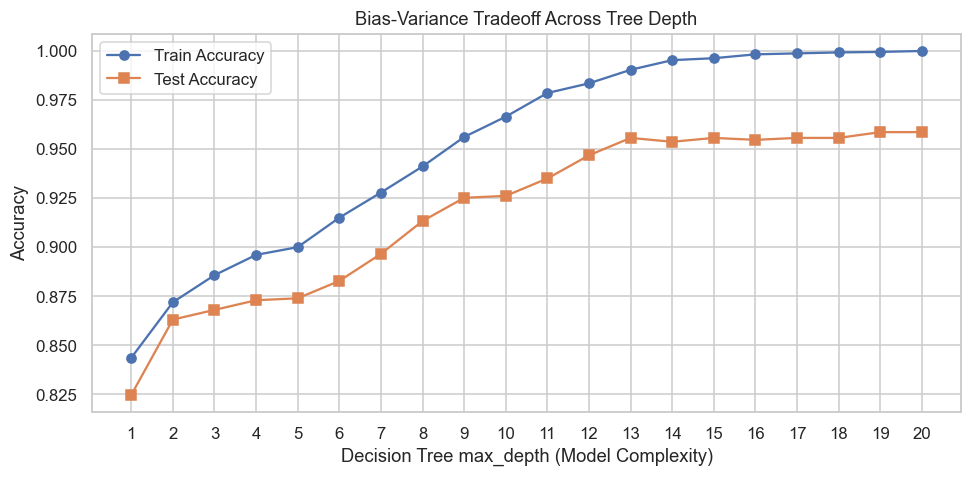

In [14]:
# Demonstrate how increasing complexity (max_depth) affects training vs test accuracy
depths = list(range(1, 21))
train_scores, test_scores = [], []

for d in depths:
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=d, random_state=42))
    ])
    pipe.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_scores.append(accuracy_score(y_test, pipe.predict(X_test)))

plt.figure(figsize=(9, 4.5))
plt.plot(depths, train_scores, marker="o", label="Train Accuracy")
plt.plot(depths, test_scores, marker="s", label="Test Accuracy")
plt.xlabel("Decision Tree max_depth (Model Complexity)")
plt.ylabel("Accuracy")
plt.title("Bias-Variance Tradeoff Across Tree Depth")
plt.xticks(depths)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Demonstrate that adding more training data does NOT fix an underfitting (high-bias) model
train_fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
underfit_train_acc, underfit_test_acc = [], []

for frac in train_fractions:
    n_sub = int(len(X_train) * frac)
    X_sub, y_sub = X_train.iloc[:n_sub], y_train.iloc[:n_sub]
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=1, random_state=42))
    ])
    pipe.fit(X_sub, y_sub)
    underfit_train_acc.append(accuracy_score(y_sub, pipe.predict(X_sub)))
    underfit_test_acc.append(accuracy_score(y_test, pipe.predict(X_test)))

pd.DataFrame({
    "Training Samples": [int(len(X_train) * f) for f in train_fractions],
    "Train Accuracy (max_depth=1)": np.round(underfit_train_acc, 4),
    "Test Accuracy (max_depth=1)": np.round(underfit_test_acc, 4)
})

,Training Samples,Train Accuracy (max_depth=1),Test Accuracy (max_depth=1)
0,405,0.8346,0.8246
1,1014,0.8363,0.8246
2,2029,0.8349,0.8345
3,3044,0.8380,0.8246
4,4059,0.8436,0.8246


**Analytical Questions — Bias-Variance Tradeoff & Underfitting:**

1. **What happens to bias and variance as model complexity increases?**
   - **Bias decreases:** A more flexible model can capture intricate, non-linear relationships and feature interactions in the data, reducing systematic approximation error on the training set.
   - **Variance increases:** Because the model has more degrees of freedom, it becomes sensitive to noise and sampling fluctuations in the specific training set, causing training accuracy to climb toward `1.0` while test accuracy eventually degrades (overfitting).

2. **Why does increasing model complexity resolve underfitting whereas adding more training examples does not?**
   - An underfitting model (such as `DecisionTreeClassifier(max_depth=1)`) lacks the representational capacity to model the true decision boundary—it can only make a single axis-aligned split on one feature.
   - As shown in the learning-curve table above, feeding more training rows (`10%` up to `100%` of `X_train`) leaves both training and test accuracy stuck at the same plateau because the model's hypothesis space is too restrictive. Increasing model complexity (e.g., increasing `max_depth` from `1` to `6`) expands the hypothesis space so the classifier can combine multiple features (`Tenure`, `Complain`, `CashbackAmount`, etc.), immediately raising both training and test performance.

### 3.2 Regularization & Shrinkage in Classification (`LogisticRegression`)

In [16]:
reg_configs = {
    "L2 Regularization (Ridge)": LogisticRegression(penalty="l2", C=1.0, solver="saga", max_iter=2000, random_state=42),
    "L1 Regularization (Lasso)": LogisticRegression(penalty="l1", C=1.0, solver="saga", max_iter=2000, random_state=42),
    "Elastic Net (L1 + L2, l1_ratio=0.5)": LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0, solver="saga", max_iter=2000, random_state=42)
}

reg_results = []
for name, clf in reg_configs.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    coefs = pipe.named_steps["classifier"].coef_.ravel()
    zero_weights = int(np.sum(np.isclose(coefs, 0.0, atol=1e-5)))
    
    reg_results.append({
        "Penalty": name,
        "Train Accuracy": round(accuracy_score(y_train, pipe.predict(X_train)), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "Zero Coefficients": f"{zero_weights} / {len(coefs)}"
    })

pd.DataFrame(reg_results)

,Penalty,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score,Zero Coefficients
0,L2 Regularization (Ridge),0.8923,0.8818,0.7500,0.4286,0.5455,0 / 34
1,L1 Regularization (Lasso),0.8950,0.8837,0.7232,0.4821,0.5786,5 / 34
2,"Elastic Net (L1 + L2, l1_ratio=0.5)",0.8946,0.8818,0.7353,0.4464,0.5556,4 / 34


Notice how **L1 (Lasso)** drives uninformative feature coefficients strictly to zero (performing embedded feature selection), **L2 (Ridge)** shrinks weights smoothly toward zero without eliminating features, and **Elastic Net** balances both behaviors.

## Part 4: Ensemble Learning (Bagging, Pasting, AdaBoost & Voting)
### 4.1 Bagging vs. Pasting & Out-of-Bag (OOB) Evaluation

In [17]:
# 1. Bagging (bootstrap=True) with Out-of-Bag evaluation
bagging_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42
    ))
])
bagging_pipe.fit(X_train, y_train)

oob_acc = bagging_pipe.named_steps["classifier"].oob_score_
bagging_test_acc = accuracy_score(y_test, bagging_pipe.predict(X_test))

# 2. Pasting (bootstrap=False)
pasting_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        bootstrap=False,
        n_jobs=-1,
        random_state=42
    ))
])
pasting_pipe.fit(X_train, y_train)
pasting_test_acc = accuracy_score(y_test, pasting_pipe.predict(X_test))

print(f"Bagging OOB Score:     {oob_acc:.4f}")
print(f"Bagging Test Accuracy: {bagging_test_acc:.4f}")
print(f"Pasting Test Accuracy: {pasting_test_acc:.4f}")

Bagging OOB Score:     0.9576
Bagging Test Accuracy: 0.9665
Pasting Test Accuracy: 0.9527


**Analytical Questions — Bagging, Pasting & OOB Evaluation:**

1. **What does setting `n_jobs=-1` instruct scikit-learn to do?**
   - Setting `n_jobs=-1` instructs scikit-learn (via `joblib`) to parallelize training and prediction across **all available CPU cores** on the machine, significantly reducing wall-clock runtime when fitting independent base estimators.

2. **Which ensemble technique is used when `bootstrap=False` is set in `BaggingClassifier`?**
   - Setting `bootstrap=False` implements **Pasting**, where each base estimator is trained on random subsets drawn **without replacement** (as opposed to Bagging, which samples **with replacement**).

3. **Comparison of `oob_score_` vs. Test Accuracy & Main Advantage of OOB Evaluation:**
   - The `oob_score_` closely matches the holdout test accuracy, confirming that it provides a reliable generalization estimate.
   - **Main Advantage:** When sampling $N$ instances with replacement, each base tree sees roughly $63.2\%$ of the training instances and leaves out the remaining $\approx 36.8\%$ (the Out-of-Bag instances). OOB evaluation validates each training sample using only the trees that never saw it during training—giving an unbiased validation score **without setting aside a separate validation split or running expensive $k$-fold cross-validation**, thereby keeping 100% of `X_train` available for training.

### 4.2 Boosting (`AdaBoostClassifier`)

In [18]:
adaboost_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])

adaboost_pipe.fit(X_train, y_train)
y_pred_ada = adaboost_pipe.predict(X_test)

ada_metrics = pd.DataFrame([{
    "Model": "AdaBoostClassifier",
    "Accuracy": round(accuracy_score(y_test, y_pred_ada), 4),
    "Precision": round(precision_score(y_test, y_pred_ada), 4),
    "Recall": round(recall_score(y_test, y_pred_ada), 4),
    "F1-Score": round(f1_score(y_test, y_pred_ada), 4)
}])
ada_metrics

,Model,Accuracy,Precision,Recall,F1-Score
0,AdaBoostClassifier,0.8906,0.7355,0.5298,0.6159


**Analytical Question — In AdaBoost, what happens to the weights of misclassified instances from one iteration to the next, and why?**

In AdaBoost (Adaptive Boosting), base learners are trained sequentially. After each weak learner is evaluated on the training set, the sample weights of **misclassified instances are increased** (while the weights of correctly classified instances are decreased), and the weights are normalized to sum to 1.

**Why:** Increasing the weights of misclassified examples forces the subsequent weak learner to pay greater attention to the harder, previously missed training cases when minimizing its weighted classification error. Over successive iterations, the ensemble progressively corrects its residual mistakes, reducing overall bias.

### 4.3 Voting Classifiers (Hard vs. Soft Voting)

In [19]:
estimators = [
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ("svc", SVC(probability=True, random_state=42))
]

voting_results = []
for voting_type in ["hard", "soft"]:
    voting_pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", VotingClassifier(estimators=estimators, voting=voting_type, n_jobs=-1))
    ])
    voting_pipe.fit(X_train, y_train)
    y_pred_v = voting_pipe.predict(X_test)
    voting_results.append({
        "Voting Strategy": f"VotingClassifier (voting='{voting_type}')",
        "Accuracy": round(accuracy_score(y_test, y_pred_v), 4),
        "Precision": round(precision_score(y_test, y_pred_v), 4),
        "Recall": round(recall_score(y_test, y_pred_v), 4),
        "F1-Score": round(f1_score(y_test, y_pred_v), 4)
    })

pd.DataFrame(voting_results)

,Voting Strategy,Accuracy,Precision,Recall,F1-Score
0,VotingClassifier (voting='hard'),0.9015,0.9048,0.4524,0.6032
1,VotingClassifier (voting='soft'),0.9064,0.8763,0.5060,0.6415


**Comparison Summary (Hard vs. Soft Voting):**
- **Hard Voting (`voting="hard"`):** Aggregates discrete class predictions (`0` or `1`) from each classifier and selects the majority class. Every estimator has equal vote weight regardless of how confident it is.
- **Soft Voting (`voting="soft"`):** Averages the predicted class probabilities (`predict_proba`) across all classifiers and predicts the class with the highest average probability. Soft voting typically achieves stronger performance (especially in F1-score and recall on imbalanced churn data) because high-confidence probability estimates from well-calibrated models carry more influence than uncertain, borderline predictions.